In [1]:
import os, sys, tempfile, subprocess
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
# from sidm.studies.dy_jets import function_dy

utilities.set_plot_style()
%matplotlib inline

In [2]:
channels=  [ 
    "cr_Zmumu_noLJ",
    "cr_Zmumu_noLJ_prompt",
    "cr_Zmumu_noLJ_displaced",
           ]

samples_separate = ["TTJets",
               "DYJetsToLL",
               "QCD",
               "Diboson",
              # "data"
              ]
samples = ["bgs", "data", "TTJets",
               "DYJetsToLL",
               "QCD",
               "Diboson",]
sum_hist= {}
for channel_name in channels:
    sum_hist[channel_name] = {}
for s in samples:
    if s == "data":
        list1= functions.get_data_files()
        list1 =  [x for x in list1 if "C" in x]
    elif s == "bgs":
        list1=[]
        for y in samples_separate:
            list2 = functions.get_bg_file_names(y)
            list1.extend(list2)
    else:
        list1 = functions.get_bg_file_names(s)
    for channel_name in channels:
        folder_name = f"OutputFiles/{channel_name}"
        sum_h= utilities.sum_hist(list1, folder_name)
        sum_hist[channel_name][s] = sum_h



In [3]:
sum_hist["cr_Zmumu_noLJ_displaced"].keys()

dict_keys(['bgs', 'data', 'TTJets', 'DYJetsToLL', 'QCD', 'Diboson'])

/uscms_data/d3/mjose/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()
/uscms_data/d3/mjose/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()


[2.76381321e-03 2.75077817e-03 2.67636865e-03 2.87345098e-03
 3.89604590e-03 3.77023983e-03 8.51359643e-03 1.09925762e-02
 4.92808302e-03 8.30557113e-03 9.43510075e-06 1.91255878e-02
 0.00000000e+00 2.90375828e-05 0.00000000e+00 7.34107134e-05]
[0.00364347 0.00385283 0.00425891 0.00462903 0.00401152 0.0057328
 0.00422164 0.00622407 0.00365631 0.00626959 0.         0.
 0.         0.01785714 0.         0.        ]


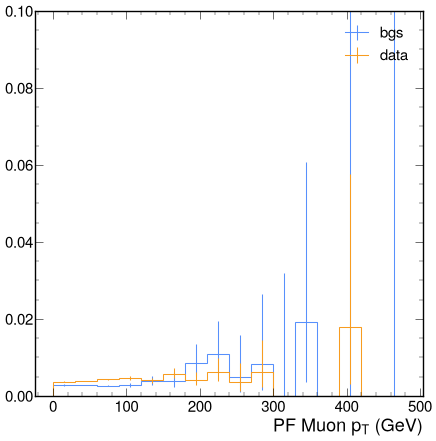

In [4]:
binning =2j
def plot_ratio_disp(histogram_name, binning=1j):
    for i, s in enumerate(samples[:2]):
        # ax =  axs[i]
        num_hist = sum_hist["cr_Zmumu_noLJ_displaced"][s][histogram_name]["cr_Zmumu_noLJ_displaced", ::binning]
        den_hist = sum_hist["cr_Zmumu_noLJ"][s][histogram_name]["cr_Zmumu_noLJ", ::binning]
        try:
            effi, err = utilities.get_eff_hist(num_hist, den_hist)
            utilities.plot(effi, yerr=err,label = s, skip_label=True)
            print(effi.values())
        except:
            print(f"using gaussian ratio for {s}")
            effi, err= utilities._gaussian_ratio(num_hist, den_hist)
            utilities.plot(effi,yerr=err, label = s, skip_label=True)
            
# plt.ylim(0, 10)
    plt.legend()

    # plt.yscale("log")
    plt.ylim(0, 0.1)
    plt.show()
hist_list = ["muon_pt"]
for histogram_name in hist_list:
    plot_ratio_disp (histogram_name, binning=6j)

[0.87712419 0.89971053 0.89756453 0.89782929 0.89945617 0.90864427
 0.89449982 0.89889464 0.90030733 0.88285272 0.85272371 0.90255857
 0.93091779 0.99818851 0.93814998 0.997055  ]
[0.84572155 0.87896858 0.87663036 0.87294445 0.8786258  0.87961117
 0.87124011 0.87551867 0.89213894 0.89028213 0.91666667 0.89830508
 0.89411765 0.89285714 0.94285714 1.        ]
using gaussian ratio for TTJets
[0.87834067 0.89977899 0.89730501 0.89790276 0.89987901 0.90653495
 0.89337176 0.89915966 0.90049751 0.88333333 0.85074627 0.90196078
 0.93103448 1.         0.9375     1.        ]
using gaussian ratio for QCD
[0.87842321 0.8997915  0.90148358 0.90082466 0.90036642 0.9101449
 0.91195197 0.89101687 0.87631225 0.91307102 0.9163526  0.90249378
 0.92817724 0.93021729 0.96733677 0.92915571]


/uscms_data/d3/mjose/SIDM/sidm/tools/utilities.py:190: RuntimeWarning: invalid value encountered in divide
  eff_values = num_vals/denom_vals
/uscms_data/d3/mjose/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()
/uscms_data/d3/mjose/SIDM/sidm/tools/utilities.py:196: RuntimeWarning: invalid value encountered in divide
  denom_counts = denom_vals**2 / denom_hist.variances()


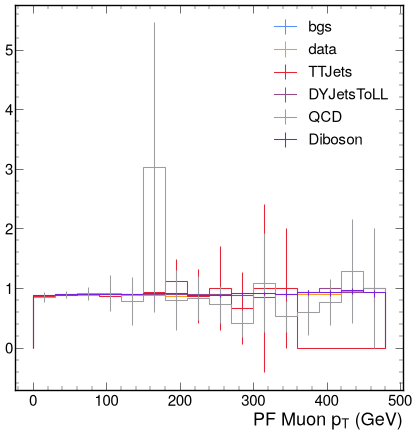

In [5]:
binning =2j
def plot_ratio_prompt(histogram_name, binning=1j):
    for i, s in enumerate(samples):
        # ax =  axs[i]
        num_hist = sum_hist["cr_Zmumu_noLJ_prompt"][s][histogram_name]["cr_Zmumu_noLJ_prompt", ::binning]
        den_hist = sum_hist["cr_Zmumu_noLJ"][s][histogram_name]["cr_Zmumu_noLJ", ::binning]
        try:
            effi, err = utilities.get_eff_hist(num_hist, den_hist)
            utilities.plot(effi, yerr=err,label = s, skip_label=True)
            print(effi.values())
        except:
            print(f"using gaussian ratio for {s}")
            effi, err= utilities._gaussian_ratio(num_hist, den_hist)
            utilities.plot(effi,yerr=err, label = s, skip_label=True)
            
# plt.ylim(0, 10)
    plt.legend()

    # plt.yscale("log")
    plt.show()
hist_list = ["muon_pt"]
for histogram_name in hist_list:
    plot_ratio_prompt (histogram_name, binning=6j)

In [6]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure (figsize =(15,12))
for p in samples[:2]:
    prompt_hist = sum_hist["cr_Zmumu_noLJ_prompt"][p][histogram_name][
        "cr_Zmumu_noLJ_prompt", ::binning
    ].copy()

    disp_hist = sum_hist["cr_Zmumu_noLJ_displaced"][p][histogram_name][
        "cr_Zmumu_noLJ_displaced", ::binning
    ].copy()

    prompt_hist = function_dy.normalize_hist(prompt_hist)
    disp_hist = function_dy.normalize_hist(disp_hist)

    ratio, err = utilities._gaussian_ratio(disp_hist, prompt_hist)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True)

plt.legend()
plt.ylabel("Displaced / Prompt")
# plt.title("Normalized displaced / Normalized prompt")
plt.show()

NameError: name 'function_dy' is not defined

<Figure size 750x600 with 0 Axes>

In [ ]:
fig, axs = plt.subplots(1, 2, figsize = (30, 12))
for p in samples[:2]:
    histogram_prompt  = sum_hist["cr_Zmumu_noLJ_prompt"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ_prompt", :, :]
    histogram_disp  = sum_hist["cr_Zmumu_noLJ_displaced"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ_displaced", :, :]
    histogram_prompt_integrals =  function_dy.integrate_hist(histogram_prompt)
    histogram_disp_integrals =  function_dy.integrate_hist(histogram_disp)

    print(histogram_prompt_integrals, histogram_disp_integrals)

    prompt_eta = functions.plot_1d (histogram_prompt, "muons_eta" )
    prompt_phi = functions.plot_1d (histogram_prompt, "muons_phi" )
    disp_eta = functions.plot_1d (histogram_disp, "muons_eta" )
    disp_phi = functions.plot_1d (histogram_disp, "muons_phi" )

    
    prompt_hist_eta = function_dy.normalize_hist(prompt_eta)
    disp_hist_eta = function_dy.normalize_hist(disp_eta)

    prompt_hist_phi = function_dy.normalize_hist(prompt_phi)
    disp_hist_phi = function_dy.normalize_hist(disp_phi)

    ratio, err = utilities._gaussian_ratio(disp_hist_eta, prompt_hist_eta)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True, ax =axs[0])

    ratio, err = utilities._gaussian_ratio(disp_hist_phi, prompt_hist_phi)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True, ax =axs[1])


plt.legend()

axs[0].set_ylabel("Displaced / Prompt")

axs[1].set_ylabel("Displaced / Prompt")

axs [0].set_ylim(0, 4)
axs [1].set_ylim(0, 10)

axs[0].legend()
axs[0].axhline(y=1, linestyle="--", linewidth=2, color="k")
axs[1].axhline(y=1, linestyle="--", linewidth=2,  color="k")
axs[1].legend()
plt.show()

In [ ]:
fig, axs = plt.subplots(1, 2, figsize = (30, 12))
# ratio = 6.616/62.061775847
for p in samples[:2]:
    histogram  = (sum_hist["cr_Zmumu_noLJ_displaced"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ_displaced", :, :] + sum_hist["cr_Zmumu_noLJ_prompt"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ_prompt", :, :])
    histogram_disp  = sum_hist["cr_Zmumu_noLJ_displaced"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ_displaced", :, :]

    eta = functions.plot_1d (histogram, "muons_eta" )
    phi = functions.plot_1d (histogram, "muons_phi" )
    disp_eta = functions.plot_1d (histogram_disp, "muons_eta" )
    disp_phi = functions.plot_1d (histogram_disp, "muons_phi" )

    ratio, err = utilities.get_eff_hist(disp_eta, eta)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True, ax =axs[0])

    ratio, err = utilities.get_eff_hist(disp_phi, phi)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True, ax =axs[1])


plt.legend()

axs[0].set_ylabel("Displaced / (Displaced + Prompt)")

axs[1].set_ylabel("Displaced / (Displaced + Prompt)")

axs [0].set_ylim(0, 0.05)
axs [1].set_ylim(0, 0.05)

axs[0].legend()
axs[0].axhline(y=1, linestyle="--", linewidth=2, color="k")
axs[1].axhline(y=1, linestyle="--", linewidth=2,  color="k")
axs[1].legend()
plt.show()

In [ ]:
histogram_name = "muon_pt"

for s in samples:
    histogram_disp  = sum_hist["cr_Zmumu_noLJ_displaced"][s][ histogram_name]["cr_Zmumu_noLJ_displaced", :]
    integral_disp = histogram_disp.values().sum()
    histogram  = sum_hist["cr_Zmumu_noLJ"][s][histogram_name]["cr_Zmumu_noLJ", :]
    integral = histogram.values().sum()
    histogram_prompt  = sum_hist["cr_Zmumu_noLJ_prompt"][s][ histogram_name]["cr_Zmumu_noLJ_prompt", :]
    integral_prompt = histogram_prompt.values().sum()
    # print(f"{s}, integral_disp: {integral_disp}, integral_prompt: {integral_prompt}, total: {integral}")
    print(f"{s}, integral_disp: {integral_disp}, integral_prompt: {integral_prompt}, prompt+displaced:{integral_prompt+integral_disp}, total: {integral}")


# 3234.371078491211, prompt: 48695.61719894409, total: 51929.9882774353,

In [ ]:
histogram_name = "muon_trkNumPixelHits"

for s in samples:
    histogram_disp  = sum_hist["cr_Zmumu_noLJ_displaced"][s][ histogram_name]["cr_Zmumu_noLJ_displaced", :]
    integral_disp = histogram_disp.values().sum()
    histogram  = sum_hist["cr_Zmumu_noLJ"][s][histogram_name]["cr_Zmumu_noLJ", :]
    integral = histogram.values().sum()
    histogram_prompt  = sum_hist["cr_Zmumu_noLJ_prompt"][s][ histogram_name]["cr_Zmumu_noLJ_prompt", :]
    integral_prompt = histogram_prompt.values().sum()
    # print(f"{s}, integral_disp: {integral_disp}, integral_prompt: {integral_prompt}, total: {integral}")
    print(f"{s}, integral_disp: {integral_disp}, integral_prompt: {integral_prompt}, prompt+displaced:{integral_prompt+integral_disp}, total: {integral}")


ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7fb802a4e550>, cbar=<matplotlib.colorbar.Colorbar object at 0x7fb7ffc41690>, text=[])

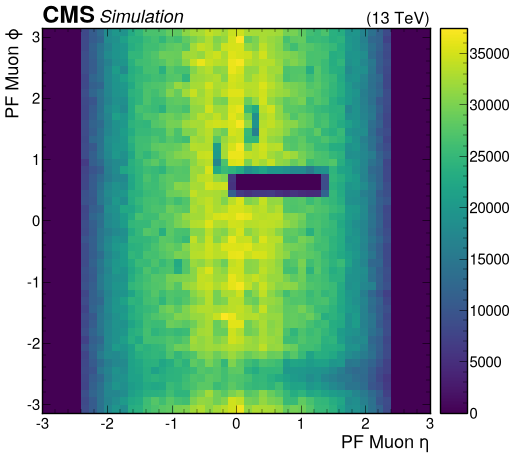

In [10]:
histogram  = sum_hist["cr_Zmumu_noLJ"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ", :, :]
utilities.plot(histogram)

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7fb7ffbbe390>, cbar=<matplotlib.colorbar.Colorbar object at 0x7fb800f19690>, text=[])

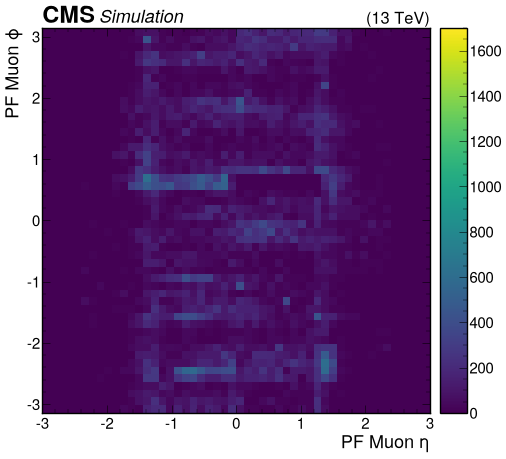

In [14]:
histogram_disp  = sum_hist["cr_Zmumu_noLJ_displaced"][p][ "muon_eta_phi"][
    "cr_Zmumu_noLJ_displaced", :, :]
from matplotlib.colors import LogNorm,Normalize
utilities.plot(histogram_disp, norm=Normalize(vmin=0, vmax=1700))

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7fb824167f50>, cbar=<matplotlib.colorbar.Colorbar object at 0x7fb802485b50>, text=[])

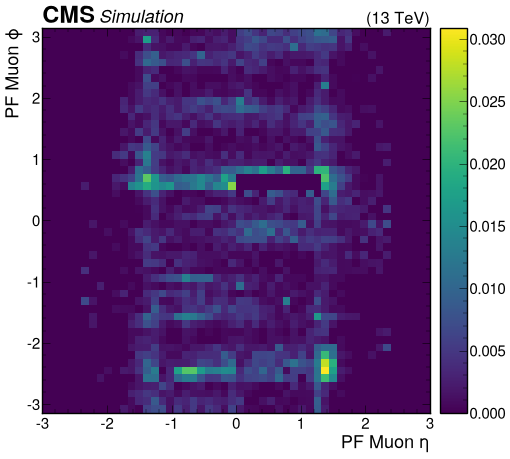

In [9]:
histogram  = sum_hist["cr_Zmumu_noLJ"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ", :, :]
histogram_disp  = sum_hist["cr_Zmumu_noLJ_displaced"][p][ "muon_eta_phi"][
    "cr_Zmumu_noLJ_displaced", :, :]

ratio, err = utilities._gaussian_ratio(histogram_disp, histogram)

# integral_disp = function_dy.integrate_hist(histogram_disp)
# print(integral_disp[0])

utilities.plot(ratio)

# utilities.plot(histogram)

In [ ]:
histogram_disp  = sum_hist["cr_Zmumu_noLJ"][p][ "jet_eta_phi"][
    "cr_Zmumu_noLJ", :, :]
utilities.plot(histogram_disp)

In [ ]:
histogram  = sum_hist["cr_Zmumu_noLJ"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ", :, :]
utilities.plot(histogram)

In [ ]:
histogram_name = "muon_trkNumPixelHits"

for s in samples:
    histogram  = sum_hist["cr_Zmumu_noLJ"][s][ histogram_name]["cr_Zmumu_noLJ", :]
    integral_disp = histogram.values()[0:3].sum()
    integral_prompt = histogram.values()[3:].sum()
    integral = histogram.values().sum()
    print(f"{s}, integral_disp: {integral_disp}, integral_prompt: {integral_prompt}, prompt+displaced:{integral_prompt+integral_disp}, total: {integral}")


In [ ]:
sum_hist.keys()